# 02 - Training both models  (RUN ON: **DGX B200** - JupyterLab, or any GPU machine)

Trains **Model 1** (CNN from scratch) and **Model 2** (MobileNetV2 transfer learning) on the split made in notebook 01,
using all visible GPUs (`tf.distribute.MirroredStrategy`).

> Prefer the terminal? The same steps are `bash scripts/run_dgx_pipeline.sh` (see `docs/DGX_B200_GUIDE.md`).

**Before running:** `data/splits/` and the images (`data/raw/`) must be on this machine (unzip `fruit_data_bundle.zip`).
Choose a hardware profile below. Training results are produced by *your* run - nothing in this notebook is pre-filled.

In [2]:
# ===== SETUP - run this cell first =====
import os, subprocess, sys
from pathlib import Path

# Colab only: put your GitHub repo URL here, OR leave "" and upload + unzip the project zip to /content
REPO_URL = ""

IN_COLAB = "google.colab" in sys.modules
PROJECT_DIR = Path("/home/jovyan/work/onkar1/fresh-rotten-fruit-capstone")
ZIP = Path("/content/fresh-rotten-fruit-capstone.zip")      # Colab: the project zip you uploaded to the Files panel
if not (PROJECT_DIR / "src").exists() and ZIP.exists():
    import shutil; shutil.unpack_archive(str(ZIP), "/content")
if not (PROJECT_DIR / "src").exists():
    if REPO_URL:
        subprocess.run(["git", "clone", REPO_URL, str(PROJECT_DIR)], check=True)
    else:
        raise SystemExit(f"Project folder not found: {PROJECT_DIR}. Upload fresh-rotten-fruit-capstone.zip to /content (Files panel) or set REPO_URL above, then re-run.")
if IN_COLAB and os.getenv("FRUIT_SKIP_PIP") != "1":
    # Colab already has TensorFlow/pandas/scikit-learn; only the extras are installed (never reinstall TensorFlow).
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(PROJECT_DIR / "requirements-colab.txt")], check=True)
sys.path.insert(0, str(PROJECT_DIR / "src"))
os.chdir(PROJECT_DIR)

from fruitfresh import config
print("Project:", PROJECT_DIR, "| split dir:", config.DEFAULT_SPLIT_DIR, "| work dir:", config.DEFAULT_WORK_DIR)

Project: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone | split dir: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/data/splits | work dir: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/workspace


## 1. Hardware
This must run **before** any other TensorFlow call in the kernel.

In [8]:
PROFILE = "configs/default.json"

from fruitfresh.distributed import hardware_from_profile

hw = hardware_from_profile(
    PROJECT_DIR / PROFILE,
    gpus="1",
    per_gpu_batch_size=2,
    mixed_precision="off",
    lr_scaling="none",
)

print(hw.describe())

{'device_type': 'GPU', 'num_replicas': 1, 'devices': ['/physical_device:GPU:0'], 'per_replica_batch_size': 2, 'global_batch_size': 2, 'mixed_precision': 'off', 'lr_scaling': 'none', 'strategy': 'OneDeviceStrategy'}


In [9]:
import tensorflow as tf
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
# Expect: on the DGX the list shows the GPUs you requested. [] means CPU only - run scripts/check_gpu.py

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:2', device_type='GPU')]


## 2. Load and verify data

In [10]:
import json, pandas as pd, matplotlib.pyplot as plt
from fruitfresh.data_index import get_dataset_root
from fruitfresh.splits import load_split
from fruitfresh.transfer import verify_data

DATA_ROOT = get_dataset_root()          # FRUIT_DATA_ROOT, data/raw, or a Kaggle download
print(json.dumps(verify_data(config.DEFAULT_SPLIT_DIR, DATA_ROOT), indent=2))
train_df, val_df, _ = load_split(config.DEFAULT_SPLIT_DIR)   # the TEST split is not used for training

{
  "train": {
    "images": 8280,
    "sources": 920,
    "missing": 0
  },
  "validation": {
    "images": 1782,
    "sources": 198,
    "missing": 0
  },
  "test": {
    "images": 1935,
    "sources": 215,
    "missing": 0
  }
}


In [11]:
# Offline DGX? put the MobileNetV2 weights file in assets/ (created by scripts/fetch_pretrained_weights.py on a machine with internet)
WEIGHTS_FILE = next(iter(sorted((PROJECT_DIR / "assets").glob("mobilenet_v2_weights*.h5"))), None)
PRETRAINED = os.getenv("FRUIT_NO_PRETRAINED") != "1"
SEED = config.SEED
WORK_DIR = config.DEFAULT_WORK_DIR
print("weights file:", WEIGHTS_FILE, "| pretrained:", PRETRAINED)

weights file: None | pretrained: True


## 3. Model 1 - baseline CNN (from scratch)
4 convolution blocks (32-64-128-256, each Conv-BatchNorm-ReLU x2 + MaxPool), global average pooling, dropout, softmax.
Finished runs are detected and **not retrained** (`force=True` retrains).

In [12]:
from fruitfresh.train import train_model, run_dir_for
info_cnn = train_model("baseline_cnn", train_df, val_df, DATA_ROOT, WORK_DIR, seed=SEED, hardware=hw, verbose=2)
print({k: info_cnn[k] for k in ("epochs_run", "best_epoch", "best_val_loss", "best_val_accuracy", "params", "training_seconds")})

Epoch 1/40


W0000 00:00:1792930041.677598  141096 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


4140/4140 - 48s - 12ms/step - accuracy: 0.4880 - loss: 1.2987 - val_accuracy: 0.7037 - val_loss: 0.8981 - learning_rate: 0.0010
Epoch 2/40
4140/4140 - 46s - 11ms/step - accuracy: 0.6925 - loss: 0.8236 - val_accuracy: 0.8535 - val_loss: 0.5947 - learning_rate: 0.0010
Epoch 3/40
4140/4140 - 45s - 11ms/step - accuracy: 0.7685 - loss: 0.6207 - val_accuracy: 0.8333 - val_loss: 0.7205 - learning_rate: 0.0010
Epoch 4/40
4140/4140 - 45s - 11ms/step - accuracy: 0.8068 - loss: 0.5306 - val_accuracy: 0.8013 - val_loss: 0.8953 - learning_rate: 0.0010
Epoch 5/40
4140/4140 - 46s - 11ms/step - accuracy: 0.8279 - loss: 0.4556 - val_accuracy: 0.8008 - val_loss: 0.9738 - learning_rate: 0.0010
Epoch 6/40

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
4140/4140 - 46s - 11ms/step - accuracy: 0.8494 - loss: 0.4113 - val_accuracy: 0.7963 - val_loss: 1.0552 - learning_rate: 0.0010
Epoch 7/40
4140/4140 - 45s - 11ms/step - accuracy: 0.8838 - loss: 0.3199 - val_accuracy: 0.8423 - va

## 4. Model 2 - MobileNetV2 transfer learning
Stage 1: ImageNet backbone frozen, train the new head. Stage 2: fine-tune the top 40 backbone layers at a small learning rate; BatchNorm layers stay frozen.

In [13]:
info_mn = train_model("mobilenet_v2", train_df, val_df, DATA_ROOT, WORK_DIR, seed=SEED, hardware=hw,
                      pretrained=PRETRAINED, weights_path=WEIGHTS_FILE, verbose=2)
print({k: info_mn[k] for k in ("epochs_run", "best_epoch", "best_val_loss", "best_val_accuracy", "params", "training_seconds")})
print(json.dumps(info_mn["stages"], indent=2))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10


W0000 00:00:1792931710.910662  141096 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


4140/4140 - 44s - 11ms/step - accuracy: 0.9342 - loss: 0.1780 - val_accuracy: 0.9781 - val_loss: 0.0623 - learning_rate: 0.0010
Epoch 2/10
4140/4140 - 42s - 10ms/step - accuracy: 0.9713 - loss: 0.0790 - val_accuracy: 0.9820 - val_loss: 0.0550 - learning_rate: 0.0010
Epoch 3/10
4140/4140 - 42s - 10ms/step - accuracy: 0.9721 - loss: 0.0742 - val_accuracy: 0.9624 - val_loss: 0.1092 - learning_rate: 0.0010
Epoch 4/10

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
4140/4140 - 41s - 10ms/step - accuracy: 0.9766 - loss: 0.0647 - val_accuracy: 0.9781 - val_loss: 0.0792 - learning_rate: 0.0010
Epoch 5/10
4140/4140 - 42s - 10ms/step - accuracy: 0.9813 - loss: 0.0506 - val_accuracy: 0.9860 - val_loss: 0.0475 - learning_rate: 5.0000e-04
Epoch 6/10
4140/4140 - 41s - 10ms/step - accuracy: 0.9832 - loss: 0.0442 - val_accuracy: 0.9854 - val_loss: 0.0616 - learning_rate: 5.0000e-04
Epoch 7/10
4140/4140 - 42s - 10ms/step - accuracy: 0.9821 - loss: 0.0492 - val_accuracy: 0.9

W0000 00:00:1792932101.777316  141685 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 916.48MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1792932101.790983  141685 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 923.19MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


4140/4140 - 49s - 12ms/step - accuracy: 0.9611 - loss: 0.1194 - val_accuracy: 0.9708 - val_loss: 0.0963 - learning_rate: 2.0000e-05
Epoch 2/20
4140/4140 - 47s - 11ms/step - accuracy: 0.9791 - loss: 0.0739 - val_accuracy: 0.9691 - val_loss: 0.0843 - learning_rate: 2.0000e-05
Epoch 3/20
4140/4140 - 47s - 11ms/step - accuracy: 0.9849 - loss: 0.0457 - val_accuracy: 0.9865 - val_loss: 0.0449 - learning_rate: 2.0000e-05
Epoch 4/20
4140/4140 - 47s - 11ms/step - accuracy: 0.9885 - loss: 0.0352 - val_accuracy: 0.9770 - val_loss: 0.0804 - learning_rate: 2.0000e-05
Epoch 5/20

Epoch 5: ReduceLROnPlateau reducing learning rate to 9.999999747378752e-06.
4140/4140 - 46s - 11ms/step - accuracy: 0.9914 - loss: 0.0270 - val_accuracy: 0.9691 - val_loss: 0.1077 - learning_rate: 2.0000e-05
Epoch 6/20
4140/4140 - 47s - 11ms/step - accuracy: 0.9983 - loss: 0.0060 - val_accuracy: 0.9899 - val_loss: 0.0263 - learning_rate: 1.0000e-05
Epoch 7/20
4140/4140 - 44s - 11ms/step - accuracy: 0.9966 - loss: 0.0104 - v

In [14]:
from fruitfresh.models import verify_finetuning
d = run_dir_for(WORK_DIR, "mobilenet_v2", SEED)
if (d / "stage1.keras").exists() and "finetune" in info_mn["stages"]:
    print(json.dumps(verify_finetuning(d / "stage1.keras", d / "model.keras"), indent=2))   # which layers did stage 2 really change?

{
  "backbone_layers": 154,
  "layers_with_changed_weights": 13,
  "first_changed_layer": 116,
  "last_changed_layer": 151,
  "batchnorm_layers_changed": 0
}


## 5. Training curves

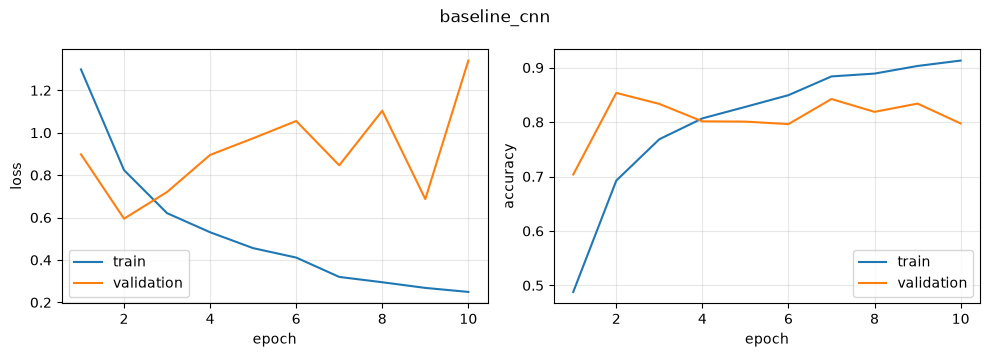

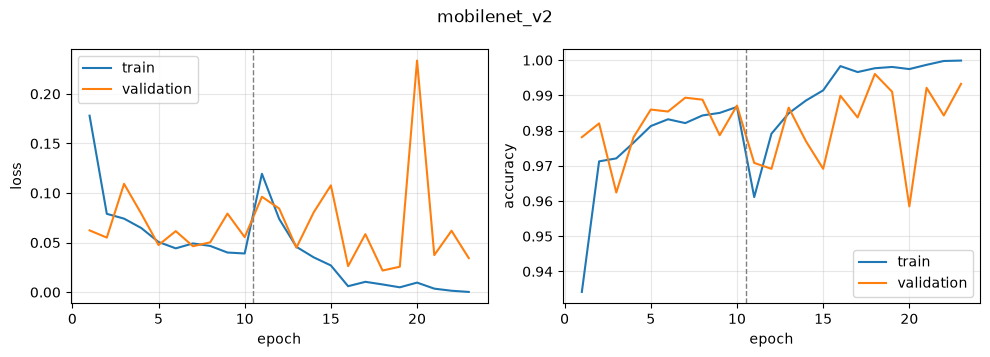

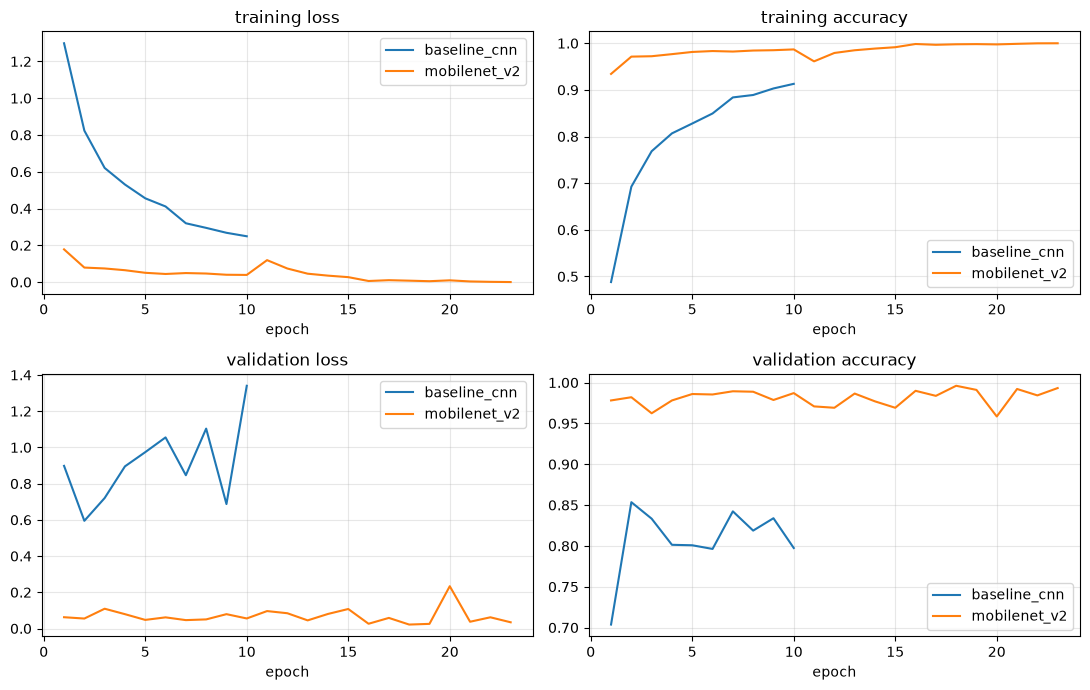

In [15]:
from fruitfresh.plots import plot_history, plot_training_curves
for name in ("baseline_cnn", "mobilenet_v2"):
    plot_history(run_dir_for(WORK_DIR, name, SEED) / "history.csv", name); plt.show()
plot_training_curves({n: run_dir_for(WORK_DIR, n, SEED) / "history.csv" for n in ("baseline_cnn", "mobilenet_v2")}); plt.show()

## 6. Optional experiments (validation only)
Set `RUN_EXPERIMENTS = True` to run one-change variants (fine-tune depth, learning rate, augmentation, ...). Each is judged on the **validation** split.

In [ ]:
RUN_EXPERIMENTS = False
EXPERIMENT_NAMES = {"mobilenet_v2": ["head_only", "ft_top20", "ft_top80"], "baseline_cnn": ["no_augmentation", "no_class_weights"]}
if RUN_EXPERIMENTS:
    from fruitfresh.experiments import run_experiments, summarize_runs, experiment_run_name, pick_best, plot_experiments
    for family, names in EXPERIMENT_NAMES.items():
        run_experiments(family, names, train_df, val_df, DATA_ROOT, WORK_DIR, SEED, pretrained=PRETRAINED,
                        weights_path=WEIGHTS_FILE if family == "mobilenet_v2" else None, hardware=hw)
        runs = [family] + [experiment_run_name(family, n) for n in names]
        table = summarize_runs(WORK_DIR, runs, SEED, val_df, DATA_ROOT)
        display(table); print("best on validation:", pick_best(table)["run"]); plot_experiments(table, family); plt.show()

## 7. Done - what to do next
* Evaluate and compare: notebook 03 (or `python scripts/evaluate.py && python scripts/compare.py`).
* Copy results back to your laptop: `python scripts/package_results.py --out dgx_results.zip` (see `docs/DGX_B200_GUIDE.md`).